# 09 Preferred slip model: 3D elastic structure (SFSVM) and PyLith Green's functions

```
Author: Danielle Lindsay
Environment: environment.yml. Runs after 07. About 45 min (30 solves for the L-curve, 100 for the Monte Carlo).
```

**What this notebook does**

1. Solves the preferred slip model with the settings of `model_config.py` (sections 3 to 6): the PyLith Green's
   functions of the run `model_config.gf_run` (3D SFSVM elastic structure, fault dipping 70° to the west), the samples
   and noise model of notebook 07, equal weights, a plane solved jointly with the slip, non-negative slip, and the CSI
   exponential prior at the L-curve corner (Hansen 1992), with no surface constraint. The vertical fault on the same
   mesh is a sensitivity test (notebook 10).
2. Computes the size of the model: potency, Mw at 30 GPa and at the slip-weighted harmonic-mean SFSVM rigidity
   (Hanks & Kanamori 1979; Vavrycuk 2013), and depth50 and depth90, the depths above which 50 % and 90 % of the
   potency lie (section 6).
3. Compares the model with the homogeneous model of notebook 08 and measures the near-fault deflection on each side
   (sections 7 to 9).
4. Draws the supplementary figures of the model (section 10).
5. Estimates the uncertainty from data noise with a Monte Carlo of correlated noise (section 11).
6. Computes the stress drop from the fixed-depth scan (section 12; Knopoff 1958; Kanamori & Anderson 1975).

**PyLith files.** No notebook builds a mesh or runs PyLith. The meshes are built by
`pylith/build/generate_gmsh_vertical.py` and `pylith/build/generate_gmsh_dip.py`, and the Green's functions are
computed by `pylith/run_gf.sh`. Both are run by hand, as documented in `pylith/README.md`. This notebook reads the
stored G matrix of the run and lists its files (section 2).

**Inputs**: notebook 07 `model_data.npz`; notebook 08 `homogeneous_model.npz`, `homogeneous_lcurve.csv`; the PyLith products listed
in section 2; notebook 06 `fig2_inputs.npz` (profile lines); notebook 04 `section_lengths.csv`,
`event_fraction_by_crossing.csv`, `creep_events.csv`; the stored outputs of `scripts/sensitivity/` listed in
`model_config.archived` (the fine-mesh baseline row of the sensitivity table, for a check, and the fixed-depth scan).

**Outputs** (`outputs/09_model_3d/`): `selected_lcurve.csv`, `selected_model.npz` (slip, prediction, plane, residual
and crossing steps; Fig 2 reads it), `rigidity_beside_fault.csv`, `model_comparison.csv`,
`montecarlo_realisations.csv`, `montecarlo_summary.csv`, `stress_drop.csv`, `near_fault_deflection.csv`,
`09_selected_stats.txt`. **Registry keys** `09_*`.

**Figures** (`Figures_<fig_date>/`, each name ending in the dip of the model, `model_config.selected_dip_tag`, e.g.
`_dip70w`): `figS_model_lcurve`, `figS_model_slip`, `figS_model_fit_maps`, `figS_model_profiles`,
`figS_model_montecarlo`; `figS_pylith_materials_sfcvm_v26` (`scripts/model_plots/plot_materials.py`).

**What to check**
- Section 2: every PyLith file exists, including the completion marker of the run.
- Section 5: the check that the corners and the numbers equal the baseline row of
  `scripts/sensitivity/sensitivity_rows.py` passes.
- Section 6: the printed Mw at 30 GPa and at the harmonic-mean SFSVM rigidity, and depth50 and depth90.
- Section 11: the printed Monte Carlo spread, and the Monte Carlo mean against the model value.
- Section 12: the check that the best row of the fixed-depth scan, solved again here, equals the stored scan passes.

## 1. Imports, settings and the number registry

The settings are printed from `model_config.summary()` so that the executed notebook records them.

In [1]:
import os
import sys
import time
import warnings

import numpy as np
import pandas as pd
import pyproj
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.collections import PolyCollection
from cmcrameri import cm as cmc

warnings.filterwarnings("ignore", category=DeprecationWarning)   # library noise only; numerical warnings stay visible
warnings.filterwarnings("ignore", category=FutureWarning)
from TulePond_filepaths import common_paths, repo_dir, paths_out, paths_sfcvm, model_crs
import insar_utils as utils
import model_config as cfg                          # the settings of the slip models
import model_utils                                  # the modelling functions

notebook = "09_model_3d"
out_dir = paths_out[notebook]
dir_07 = paths_out["07_model_data"]
dir_hom = paths_out["08_model_homogeneous"]
field_dir = paths_out["06_event_field_geometry"]
events_dir = paths_out["04_event_detection"]
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
made = time.strftime("%Y-%m-%d %H:%M")
creep_lo_km, creep_hi_km = cfg.sse_section_km()
band_lo_km, band_hi_km = cfg.band90_km()
model_data_file = os.path.join(dir_07, "model_data.npz")
homogeneous_file = os.path.join(dir_hom, "homogeneous_model.npz")
fig2_inputs_file = os.path.join(field_dir, "fig2_inputs.npz")
crossings_file = os.path.join(events_dir, "event_fraction_by_crossing.csv")
REG = utils.Registry(notebook, common_paths, repo_dir)
REG.inputs(model_data_file, homogeneous_file, os.path.join(dir_hom, "homogeneous_lcurve.csv"), fig2_inputs_file, crossings_file,
           os.path.join(events_dir, "section_lengths.csv"), os.path.join(events_dir, "creep_events.csv"), cfg.gf_files["G"],
           cfg.archived["sensitivity_rows"], cfg.archived["depth_scan"])
OKABE = dict(blue="#0072B2", orange="#E69F00", vermillion="#D55E00", purple="#CC79A7", black="#000000", grey="#999999")
utils.mpl_paper_style(base=7)
cm = 1 / 2.54
print("\n".join(cfg.summary()))

Registry for 09_model_3d: run a310aaf9, git 8f39cf2+
forward model gf_shallow_dip70w_sfcvm_order2 (PyLith 5.0.2, order 2, shallow mesh, fault dipping 70 deg W, SFSVM v26.0 aligned, no Vs floor, no cap)
data: swath 4 km, km 52-67, quadtree 2 -> 30 m; near-trace cut 60 m
noise: semivariogram beyond 5 km on a 15 km swath, pairs < 8 km
weighting: diagonal, nugget^2 / N^0 (equal weights); reference frame '1,x,y' solved jointly
prior: CSI exponential, lambda (0.1, 0.05) km (effective 0.2 / 0.1 km); slip >= 0; surface constraint OFF
sigma: own L-curve corner on 21 base values + 9 around the corner
SSE section km 56.30-62.20; 90 % band km 58.20-60.20 (04 section_lengths.csv); near field +/-500 m; mu_ref 30 GPa


## 2. The PyLith files of the Green's functions

The meshes are built by `pylith/build/generate_gmsh_vertical.py` and `pylith/build/generate_gmsh_dip.py`, and the
Green's functions by `pylith/run_gf.sh`, run by hand as documented in `pylith/README.md` (PyLith 5.0.2; Aagaard et al.
2013). The notebook only reads the stored products. This section lists the inputs and outputs of the run
`model_config.gf_run` (basis order 2) with their paths and sizes: the mesh and its report, the cfg files
(`pylith/cfg/`), the SFSVM material database and the grid it was written from (Hirakawa & Aagaard 2026), the impulse
database, the output points (the samples of notebook 07), the command, the run log and completion marker, the raw
outputs, and the G matrix assembled from them. `model_utils.build_G` matches each impulse to its fault vertex and each
output point to its sample, projects the displacement on the fault-parallel look vector, and sets the right-lateral
sign.

In [2]:
pylith_files = []
for role in ("mesh", "mesh_report", "material_db", "material_grid", "impulse_db", "points", "log", "done_marker", "G"):
    pylith_files.append((role, cfg.gf_files[role]))
for path in cfg.gf_files["cfg"]:
    pylith_files.append(("cfg", os.path.join(repo_dir, path)))
for path in cfg.gf_files["outputs"]:
    pylith_files.append(("output", path))
for role, path in pylith_files:
    assert os.path.exists(path), f"missing PyLith file ({role}): {path}"
    size_mb = os.path.getsize(path) / 1e6
    print(f"{role:13s} {size_mb:9.1f} MB  {path}")
print(f"command (from the data root, queued by {cfg.gf_files['queue_script']}):\n  {cfg.gf_files['command']}")
with open(cfg.gf_files["mesh_report"]) as report:
    print("mesh report:", "".join(report.readlines()[:8]))

mesh               24.2 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_inputs/mesh/mesh_dip70w_tet_shallow.msh
mesh_report         0.0 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_inputs/mesh/mesh_dip70w_tet_shallow_report.txt
material_db       223.8 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_SFCVM/spatialdb/mat_sfcvm_v26-0_aligned_nocap.spatialdb
material_grid       7.4 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_SFCVM/spatialdb/sfcvm_v26-0_aligned_nocap_grid.npz
impulse_db          0.0 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_inputs/spatialdb/impulses_km54-65_z3000.spatialdb
points              0.1 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_inputs/points/insar_points.txt
log                 1.7 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/modeling_SFCVM/runs/gf_shallow_dip70w_sfcvm_order2.log
done_marker         0.0 MB  /Users/dlindsay/work/proj_TulePond_DISP_release/pylith_r

## 3. The data and the inversion set-up

The samples of notebook 07 (`model_data.npz`, rebuilt as a `csi.insar` data set by `model_utils.samples_from_arrays`)
and its noise model are read. `model_utils.tent_model_setup` reads the stored G (`load_G`; built from the PyLith output
by `build_G` and asserted to be on these samples and at this strike), the tent fault and its CSI template, `keep`
(the samples 60 m or more from the trace) and the near-field masks (fitted samples within 500 m west or east of the
trace in the SSE section).

The inversion (`model_utils.invert_tents`, CSI; Jolivet 2024) is that of notebook 08, section 4:

$$\min_{\mathbf{s} \ge 0,\ \mathbf{a}} \;
  (\mathbf{d} - G\mathbf{s} - B\mathbf{a})^{T} C_d^{-1} (\mathbf{d} - G\mathbf{s} - B\mathbf{a})
  + \mathbf{s}^{T} C_m^{-1} \mathbf{s}
  + (\mathbf{a} - \mathbf{a}_0)^{T} C_a^{-1} (\mathbf{a} - \mathbf{a}_0) ,$$

$$C_{m,jk} = \sigma^2 \,\frac{\lambda_0^2}{\lambda_h \lambda_v}\,
  \exp\!\left(-\frac{h_{jk}}{2\lambda_h}\right) \exp\!\left(-\frac{v_{jk}}{2\lambda_v}\right) ,$$

where $\mathbf{d}$ is the vector of fault-parallel samples (mm), $G$ the PyLith Green's functions (fault-parallel
displacement per unit right-lateral slip, m/m), $\mathbf{s}$ the right-lateral slip at the impulse vertices (mm), $B$
the plane design matrix with rows $(1, x_i, y_i)$ (sample position in km in the CSI frame), $\mathbf{a}$ the plane
coefficients (mm, mm/km, mm/km), and $C_d$ the data covariance (`model_utils.data_cd`): diagonal, with the nugget
variance $n^2$ for every fitted sample (equal weights) and $10^8 n^2$ for the samples closer than 60 m to the trace.
$C_m$ is the CSI exponential prior (Radiguet et al. 2011), with $\sigma$ the regularisation strength (mm), $h_{jk}$
and $v_{jk}$ the horizontal and vertical distances between impulse vertices $j$ and $k$ (km), $\lambda_h = 0.1$ km
and $\lambda_v = 0.05$ km the correlation lengths along strike and down dip, and $\lambda_0$ a normalising length that
CSI computes from the vertex spacing (km). $C_a = 10^4 I$ and $\mathbf{a}_0 = -10^3$ form a weak prior on the plane,
which lets the non-negative least-squares solver give the plane coefficients either sign.

In [3]:
model_data = np.load(model_data_file)
field_fingerprint = model_utils.field_fingerprint(os.path.join(field_dir, "fp_maps.npz"))
assert str(model_data["field_fingerprint"]) == field_fingerprint, "07's model data were made from another 06 field: re-run 07"
frame_lonlat = tuple(model_data["frame_lonlat"])
strike_deg = float(model_data["strike_deg"])
look = model_data["look"]
cov_p = model_data["cov_p"]
assert float(model_data["nugget_power"]) == cfg.nugget_power
profile_lats = pd.read_csv(common_paths["fault_profiles"]).ft_lat.values
trace = model_utils.model_trace(model_data["trace_lonlat"], -90.0, 90.0, frame_lonlat, profile_lats,
                                every_km=float(model_data["trace_every_km"]))
trace_xy_m = (trace["x_km"] * 1e3, trace["y_km"] * 1e3)
samples = model_utils.samples_from_arrays("fault-parallel samples", model_data["sample_lon"], model_data["sample_lat"],
                                          model_data["sample_x_km"], model_data["sample_y_km"], model_data["data_mm"],
                                          model_data["wgt"], look, frame_lonlat, cov_p, cfg.nugget_power)
setup = model_utils.tent_model_setup({"sfcvm": cfg.gf_run}, str(model_data["points_default"]), strike_deg,
                                     {"sfcvm": (cfg.gf_pylith_output_dir, cfg.gf_gf_dir)}, cfg.km_window, creep_lo_km, creep_hi_km,
                                     trace_xy_m, frame_lonlat, model_crs, profile_lats, cfg.near_trace_cut_km, cfg.near_field_km,
                                     trace["km_pp"])
G = setup["G"]["sfcvm"]
tents = setup["tents"]
keep, west_near, east_near = setup["keep"], setup["west_near"], setup["east_near"]
signed_d_km, sample_km_pp = setup["signed_d_km"], setup["sample_km_pp"]
assert np.array_equal(setup["points"]["lon"], model_data["sample_lon"]), "G is not on 07's samples"
Cd = model_utils.data_cd(cfg.weighting, samples, cov_p, cfg.nugget_power, keep=keep)
print(f"G {G.shape} (samples x tents), max |G| {np.abs(G).max():.3f} m/m; {keep.sum()} fitted samples of {keep.size}; "
      f"near field {west_near.sum()} west / {east_near.sum()} east; sample sd {np.sqrt(cov_p[0]):.3f} mm (nugget)")


def solve_3d(sigma, vel=None):
    """Solve the 3D model at one regularisation strength.

    Parameters
    ----------
    sigma : float
        Regularisation strength of the CSI exponential prior (mm).
    vel : numpy.ndarray, optional
        Data (mm) that replace the samples, as in the Monte Carlo realisations.

    Returns
    -------
    tuple
        (fault, InSAR data set, None) from `model_utils.invert_tents`.
    """
    return model_utils.invert_tents(setup["template"], samples, G, Cd, None, None, sigma, cfg.lam_xz_km, frame_lonlat,
                                    use_surface=cfg.use_surface, vel_insar=vel, name=f"3D sigma {sigma:.3f}", ramp_spec=cfg.ramp_spec)

G (2386, 3560) (samples x tents), max |G| 0.651 m/m; 1787 fitted samples of 2386; near field 366 west / 334 east; sample sd 0.903 mm (nugget)


## 4. The rigidity beside the fault

The shear modulus used by PyLith is read from the run's `-elastic_info.h5` (materials basis order 1, so the cell value
is the mean of its vertex values). It is compared with the SFSVM grid it was read from, $\mu = \rho v_s^2$ with
$\rho$ the density (kg/m$^3$) and $v_s$ the S-wave speed (m/s); the median relative difference must be below 5 %
(asserted). For each fault triangle, the nearest PyLith cell on each side of the fault is taken
(`model_utils.mu_beside_fault`). The rigidity of a fault between two materials is their harmonic mean (Vavrycuk 2013;
`model_utils.harmonic_mean_rigidity`),

$$\mu_t = \frac{2\,\mu_{W,t}\,\mu_{E,t}}{\mu_{W,t} + \mu_{E,t}} ,$$

where $\mu_{W,t}$ and $\mu_{E,t}$ are the shear moduli (Pa) of the cells west and east of triangle $t$. The Mw with
the SFSVM rigidity uses the value $\mu_t$ of each triangle (section 6).

In [4]:
elastic_info = os.path.join(cfg.gf_pylith_output_dir, f"{cfg.gf_run}-elastic_info.h5")
mu_mean, mu_west, mu_east, mu_rel_median = model_utils.mu_beside_fault(elastic_info, cfg.sfcvm_grid_npz, tents, cfg.gf_run)
assert mu_rel_median < 0.05, "PyLith's cell rigidity differs from the SFSVM grid by more than 5 % (median)"
mu_harmonic = model_utils.harmonic_mean_rigidity(mu_west, mu_east)
rigidity = pd.DataFrame(dict(tri_km=tents.tri_km, tri_depth_m=tents.tri_depth_m, tri_area_m2=tents.tri_area,
                             mu_west_gpa=mu_west / 1e9, mu_east_gpa=mu_east / 1e9, mu_harmonic_gpa=mu_harmonic / 1e9))
rigidity.to_csv(os.path.join(out_dir, "rigidity_beside_fault.csv"), index=False)
top_section = (tents.tri_depth_m < 100) & (tents.tri_km >= creep_lo_km) & (tents.tri_km <= creep_hi_km)
print(f"SSE section, top 100 m: median mu west {np.median(mu_west[top_section]) / 1e9:.3f}, east "
      f"{np.median(mu_east[top_section]) / 1e9:.3f}, harmonic {np.median(mu_harmonic[top_section]) / 1e9:.3f} GPa")

gf_shallow_dip70w_sfcvm_order2: PyLith cell mu vs grid at centroids (318615 cells in the fine box, top 1.5 km): median |rel diff| 0.000, 90th pct 0.194; PyLith mu range 0.043-64.5 GPa


gf_shallow_dip70w_sfcvm_order2: fault-adjacent mu, top 100 m median: west 0.510, east 0.913 GPa
SSE section, top 100 m: median mu west 0.447, east 0.819, harmonic 0.571 GPa


## 5. L-curve, corner, and an independent check

The regularisation strength is the corner of the model's own L-curve (`model_utils.own_corner`; Hansen 1992), found
as in notebook 08, section 5. For each $\sigma$ the L-curve takes the weighted misfit of the fitted samples and the
prior-weighted roughness of the slip,

$$\chi^2 = \mathbf{r}_K^{T} C_{d,K}^{-1} \mathbf{r}_K , \qquad
  R = \sqrt{\mathbf{s}^{T} \left(C_m / \sigma^2\right)^{-1} \mathbf{s}} ,$$

where $\mathbf{r}_K = \mathbf{d} - G\mathbf{s} - B\mathbf{a}$ is the residual over the fitted samples $K$ (mm) and
$C_{d,K}$ their data covariance. With $x = \log_{10}\sqrt{\chi^2}$ and $y = \log_{10} R$ as cubic splines of
$\log_{10}\sigma$, the corner is the $\sigma$ of maximum curvature

$$\kappa = \frac{\lvert x' y'' - y' x'' \rvert}{\left(x'^2 + y'^2\right)^{3/2}} ,$$

where the primes are derivatives with respect to $\log_{10}\sigma$, evaluated at 400 points between the second and
the second-last $\sigma$ of the grid. The corner is found first on the base grid, then on the base grid plus nine
values $\sigma_c \, 2^{k/16}$ ($k = -4, \dots, 4$) around the first corner $\sigma_c$; the second corner is the
model's $\sigma$.

Check: `scripts/sensitivity/sensitivity_rows.py` solves the same run with the same rule in a separate script (row
"Baseline (fine mesh, 70 W)", stored in `model_config.archived`). The corners and the model must reproduce that row:
$\sigma$, Mw, RMS of all fitted samples and within 500 m west and east, peak slip and its depth, and depth50 and
depth90.

In [5]:
t0 = time.time()
sigma, sigma_base, lcurve = model_utils.own_corner(solve_3d, cfg.sigma_grid_base, cfg.sigma_refine_factors, tents, cfg.mu_ref_pa,
                                                   "3D SFSVM", keep)
lcurve.assign(corner=sigma, base_corner=sigma_base).to_csv(os.path.join(out_dir, "selected_lcurve.csv"), index=False)
print(f"corner {sigma:.3f} (base grid {sigma_base:.3f}); {len(lcurve)} solves in {(time.time() - t0) / 60:.1f} min")

sweep = pd.read_csv(cfg.archived["sensitivity_rows"])
sweep_row = sweep[(sweep.row == f"Baseline (fine mesh, {cfg.selected_dip_label})") & (sweep.variant == "Selected")]
assert len(sweep_row) == 1, f"no single baseline row in {cfg.archived['sensitivity_rows']}"
sweep_row = sweep_row.iloc[0]
assert sweep_row.run == cfg.gf_run and sweep_row.cut_m == cfg.near_trace_cut_km * 1e3 and sweep_row.ramp == cfg.ramp_spec
fault_check, data_check, _ = solve_3d(sigma)
check = model_utils.tent_numbers(fault_check.slip[:, 0].copy(), data_check, tents, keep, west_near, east_near, cfg.mu_ref_pa)
comparison = pd.DataFrame([("sigma, base grid", sigma_base, sweep_row.sigma_base_corner), ("sigma, refined", sigma, sweep_row.sigma),
                           ("Mw 30 GPa", check["Mw_30gpa"], sweep_row.Mw_30gpa), ("RMS all (mm)", check["rms_mm"], sweep_row.rms_mm),
                           ("RMS 500 m west (mm)", check["rms_west_mm"], sweep_row.rms_west_mm),
                           ("RMS 500 m east (mm)", check["rms_east_mm"], sweep_row.rms_east_mm),
                           ("peak slip (mm)", check["peak_slip_mm"], sweep_row.peak_slip_mm),
                           ("peak depth (m)", check["peak_depth_m"], sweep_row.peak_depth_m),
                           ("depth50 (m)", check["depth50_m"], sweep_row.depth50_m), ("depth90 (m)", check["depth90_m"], sweep_row.depth90_m)],
                          columns=["quantity", "this notebook", "sensitivity_rows.py"])
print(comparison.to_string(index=False))
assert np.allclose(comparison["this notebook"], comparison["sensitivity_rows.py"], rtol=1e-3), "the model does not reproduce the sensitivity row"
print(f"Check passed: the corners and the model reproduce the sensitivity row 'Baseline (fine mesh, {cfg.selected_dip_label})'")

  3D SFSVM [base] sigma   4.000: chi2 12843, roughness 157.1, RMS 2.422 mm, Mw30 3.244 (25 s)


  3D SFSVM [base] sigma   6.000: chi2 10164, roughness 303.8, RMS 2.155 mm, Mw30 3.439 (25 s)


  3D SFSVM [base] sigma   8.000: chi2 7854, roughness 452.8, RMS 1.894 mm, Mw30 3.559 (25 s)


  3D SFSVM [base] sigma  10.000: chi2 6110, roughness 587.5, RMS 1.671 mm, Mw30 3.639 (25 s)


  3D SFSVM [base] sigma  11.000: chi2 5435, roughness 647.6, RMS 1.576 mm, Mw30 3.670 (25 s)


  3D SFSVM [base] sigma  12.000: chi2 4872, roughness 702.8, RMS 1.492 mm, Mw30 3.695 (26 s)


... (23 outputs left out)

  3D SFSVM [refine] sigma  62.370: chi2 1700, roughness 1391.7, RMS 0.881 mm, Mw30 3.924 (23 s)


3D SFSVM: L-curve corner 52.447 on the base grid, 49.611 after refining


corner 49.611 (base grid 52.447); 30 solves in 12.1 min


           quantity  this notebook  sensitivity_rows.py
   sigma, base grid      52.446771            52.446771
     sigma, refined      49.610774            49.610774
          Mw 30 GPa       3.909233             3.909233
       RMS all (mm)       0.894919             0.894919
RMS 500 m west (mm)       0.854446             0.854446
RMS 500 m east (mm)       0.982309             0.982309
     peak slip (mm)      17.282416            17.282416
     peak depth (m)     111.449245           111.449245
        depth50 (m)     245.412013           245.412013
        depth90 (m)     694.966649           694.966649
Check passed: the corners and the model reproduce the sensitivity row 'Baseline (fine mesh, 70 W)'


## 6. The preferred model and its numbers

The model is solved at the corner $\sigma$, and `model_utils.tent_numbers` gives its numbers.

- RMS of the residual $r_i = d_i - (G\mathbf{s})_i - (B\mathbf{a})_i$ over a set of samples $S$,
  $\mathrm{RMS}_S = \sqrt{\frac{1}{|S|}\sum_{i \in S} r_i^2}$ (mm), where $S$ is the fitted samples, or the fitted
  samples within 500 m west or east of the trace in the SSE section.
- Potency, $P = \sum_t A_t \bar{s}_t$ (m$^3$), where $A_t$ is the area of fault triangle $t$ (m$^2$) and $\bar{s}_t$
  the mean of the slip at its three vertices (m), which is the integral of the linear slip over the triangle.
- Seismic moment and moment magnitude (Hanks & Kanamori 1979) at the reference rigidity, $M_0 = \mu_{ref} P$ with
  $\mu_{ref} = 30$ GPa, and with the harmonic-mean SFSVM rigidity of each triangle (section 4; Vavrycuk 2013),
  $M_0 = \sum_t \mu_t A_t \bar{s}_t$; in both cases $M_w = \frac{2}{3}\left(\log_{10} M_0 - 9.1\right)$ with $M_0$ in
  N m. The slip-weighted effective rigidity is $\mu_{eff} = M_0 / P$ (Pa).
- Peak slip, $\max_j s_j$ (mm), and the depth of its vertex (m).
- depth50 and depth90, the depths above which 50 % and 90 % of the potency lie:
  $z_q = \min\{\, z_t : \sum_{t' :\, z_{t'} \le z_t} A_{t'} \bar{s}_{t'} \ge q P \,\}$, where $z_t$ is the depth of
  the centroid of triangle $t$ (m) and $q$ is 0.5 or 0.9.

CSI removes the fitted plane from the data, so the plane at each sample is the data minus the plane-removed data. The
step of Fig 2K is then measured at each crossing $c$ of notebook 04, for the data and for the model, in the same way
(`model_utils.crossing_steps_like`):

$$\Delta u_c = \operatorname{median}_{i \in E_c} u_i - \operatorname{median}_{i \in W_c} u_i ,$$

where $u_i$ is the plane-removed data or the model at sample $i$ (mm), and $E_c$ and $W_c$ are the samples 60 to
150 m east and west of the trace within 200 m along strike of crossing $c$. The step is not defined where a side has
fewer than 3 samples. The mean and RMS of the data-minus-model step over the crossings of the 90 % band are reported.

In [6]:
fault_sel, data_sel, _ = solve_3d(sigma)
slip = fault_sel.slip[:, 0].copy()
numbers = model_utils.tent_numbers(slip, data_sel, tents, keep, west_near, east_near, cfg.mu_ref_pa, mu_harmonic)
model_mm = data_sel.synth.copy()
data_plane_removed_mm = data_sel.vel.copy()
plane_mm = samples.vel - data_plane_removed_mm
residual_mm = data_plane_removed_mm - model_mm
design = np.c_[np.ones(samples.vel.size), samples.x, samples.y]
plane_coef = np.linalg.lstsq(design, plane_mm, rcond=None)[0]
assert np.allclose(design @ plane_coef, plane_mm, atol=1e-6), "the removed reference frame is not a plane"
assert np.allclose(G @ slip, model_mm, atol=1e-6), "CSI's prediction is not G x slip"
assert np.allclose(samples.vel - plane_mm - model_mm, residual_mm), "data - plane - model != residual"
crossings = pd.read_csv(crossings_file)
crossing_km = crossings.km.values
data_step = model_utils.crossing_steps_like(data_plane_removed_mm, signed_d_km, sample_km_pp, crossing_km, cfg.fig2k_inner_km, cfg.fig2k_outer_km)
model_step = model_utils.crossing_steps_like(model_mm, signed_d_km, sample_km_pp, crossing_km, cfg.fig2k_inner_km, cfg.fig2k_outer_km)
in_band = (crossing_km >= band_lo_km) & (crossing_km <= band_hi_km) & np.isfinite(data_step) & np.isfinite(model_step)
step_residual = data_step[in_band] - model_step[in_band]
numbers.update(sigma=sigma, sigma_base_corner=sigma_base, band_step_mean_mm=float(step_residual.mean()),
               band_step_rms_mm=float(np.sqrt(np.mean(step_residual ** 2))), n_band_crossings=int(in_band.sum()),
               plane_offset_mm=float(plane_coef[0]), plane_dx_mm_per_km=float(plane_coef[1]), plane_dy_mm_per_km=float(plane_coef[2]))
for key, value in numbers.items():
    print(f"  {key:22s} {value:.5g}")

  rms_mm                 0.89492
  rms_west_mm            0.85445
  rms_east_mm            0.98231
  n_fitted               1787
  potency_m3             30671
  Mw_30gpa               3.9092
  Mw_sfcvm               3.2681
  mu_effective_gpa       3.2763
  peak_slip_mm           17.282
  peak_depth_m           111.45
  depth50_m              245.41
  depth90_m              694.97
  sigma                  49.611
  sigma_base_corner      52.447
  band_step_mean_mm      0.20569
  band_step_rms_mm       0.47731
  n_band_crossings       20
  plane_offset_mm        -0.11201
  plane_dx_mm_per_km     -0.02358
  plane_dy_mm_per_km     -0.15362


## 7. The homogeneous model of notebook 08 and the profile lines of notebook 06

The homogeneous model of notebook 08 is read and asserted to be on the same samples with the same near-trace cut. The
profile lines of notebook 06 are read for the profile figure (section 10). The X-X' profile numbers of the paper come
from the pixels in notebook 06, not from this notebook.

In [7]:
fig2_inputs = np.load(fig2_inputs_file)
homogeneous = np.load(homogeneous_file)
assert np.array_equal(homogeneous["sample_lon"], model_data["sample_lon"]) and np.array_equal(homogeneous["keep"], keep), \
    "08's homogeneous model is not on these samples / this cut"
print(f"08 homogeneous model: sigma {float(homogeneous['sigma']):.2f}, Mw {float(homogeneous['Mw_30gpa']):.3f}, n_sub {int(homogeneous['n_sub'])}")

08 homogeneous model: sigma 37.83, Mw 3.800, n_sub 8


## 8. The 3D model and the homogeneous model of notebook 08

The two models share the fault, the samples, the weighting, the plane, the prior, the near-trace cut and the corner
rule; only the Green's functions differ. Their numbers (section 6) are tabulated side by side.

In [8]:
compare_keys = ["sigma", "rms_mm", "rms_west_mm", "rms_east_mm", "potency_m3", "Mw_30gpa", "peak_slip_mm", "peak_depth_m",
                "depth50_m", "depth90_m"]
model_comparison = pd.DataFrame(dict(quantity=compare_keys, model_3d=[numbers[k] for k in compare_keys],
                                     homogeneous=[float(homogeneous[k]) for k in compare_keys]))
model_comparison.to_csv(os.path.join(out_dir, "model_comparison.csv"), index=False)
print(model_comparison.to_string(index=False))

    quantity     model_3d  homogeneous
       sigma    49.610774    37.833808
      rms_mm     0.894919     1.114384
 rms_west_mm     0.854446     1.250724
 rms_east_mm     0.982309     1.218923
  potency_m3 30671.063971 21013.327346
    Mw_30gpa     3.909233     3.799744
peak_slip_mm    17.282416    18.366173
peak_depth_m   111.449245    52.721979
   depth50_m   245.412013   170.849945
   depth90_m   694.966649   609.919430


## 9. Near-fault deflection, west and east

On each side of the fault, the near-fault deflection is the mean of the fitted samples near the trace minus the mean
of the samples farther away, in the SSE section (`model_utils.side_deflection_mm`; distances in `model_config`):

$$D_{side} = \frac{1}{|N|}\sum_{i \in N} u_i - \frac{1}{|F|}\sum_{i \in F} u_i ,$$

where $u_i$ is the value at sample $i$ (mm), $N$ the fitted samples 0.06 to 0.25 km from the trace on that side, and
$F$ the fitted samples 1.5 to 3 km from the trace on that side, both in the SSE section. It is computed for the data
(with each model's own plane removed), the 3D model and the homogeneous model, with the sample counts. The far band
holds 11 to 14 samples per side, so the deflection is also given with a far band of 1 to 3 km as a check.

In [9]:
in_section = (sample_km_pp >= creep_lo_km) & (sample_km_pp <= creep_hi_km)
deflection_fields = (("Data (3D model's plane removed)", data_plane_removed_mm), ("3D model", model_mm),
                     ("Data (homogeneous model's plane removed)", homogeneous["data_plane_removed_mm"]),
                     ("Homogeneous model", homogeneous["model_mm"]))
deflection_rows = []
for far_km, far_label in ((cfg.far_deflection_km, "selected"), (cfg.far_deflection_check_km, "check")):
    for field, values in deflection_fields:
        west = model_utils.side_deflection_mm(values, signed_d_km, in_section, keep, -1, cfg.near_deflection_km, far_km)
        east = model_utils.side_deflection_mm(values, signed_d_km, in_section, keep, 1, cfg.near_deflection_km, far_km)
        deflection_rows.append(dict(far_band=far_label, far_km=f"{far_km[0]:g}-{far_km[1]:g}", field=field, west_mm=west[0],
                                    east_mm=east[0], n_near_west=west[1], n_far_west=west[2], n_near_east=east[1], n_far_east=east[2]))
deflection = pd.DataFrame(deflection_rows)
deflection.to_csv(os.path.join(out_dir, "near_fault_deflection.csv"), index=False)
print(f"near band {cfg.near_deflection_km} km; far band {cfg.far_deflection_km} km (check {cfg.far_deflection_check_km} km)")
print(deflection.round(2).to_string(index=False))

near band (0.06, 0.25) km; far band (1.5, 3.0) km (check (1.0, 3.0) km)
far_band far_km                                    field  west_mm  east_mm  n_near_west  n_far_west  n_near_east  n_far_east
selected  1.5-3          Data (3D model's plane removed)    -4.93     1.86          294          14          284          11
selected  1.5-3                                 3D model    -5.34     1.37          294          14          284          11
selected  1.5-3 Data (homogeneous model's plane removed)    -4.68     1.67          294          14          284          11
selected  1.5-3                        Homogeneous model    -4.15     2.07          294          14          284          11
   check    1-3          Data (3D model's plane removed)    -4.80     1.51          294          24          284          20
   check    1-3                                 3D model    -5.26     1.31          294          24          284          20
   check    1-3 Data (homogeneous model's plane remov

## 10. Figures of the model: L-curves, slip, fit maps, profiles

The figures use the journal style (`insar_utils.mpl_paper_style(base=7)`, 300 dpi, png and pdf) and Okabe-Ito colours.
Everything drawn is a product of this notebook or of notebooks 07 and 08; the model profiles are $G\mathbf{s}$ at the samples.
The last figure shows the SFSVM shear modulus at 50 m depth and across X-X' (`scripts/model_plots/plot_materials.py`).

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_model_lcurve_dip70w.png


... (9 outputs left out)

1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_model_fit_maps_dip70w.png
saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_model_profiles_dip70w.png
X-X': trace point km 58.7 at (-794, 462) m; boundary offset b = 135 m


wrote /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_pylith_materials_sfcvm_v26.png


'/Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_pylith_materials_sfcvm_v26.png'

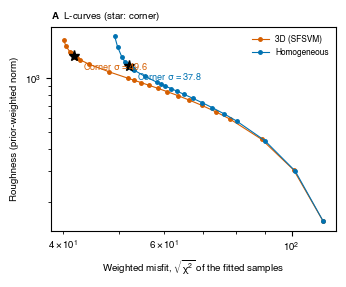

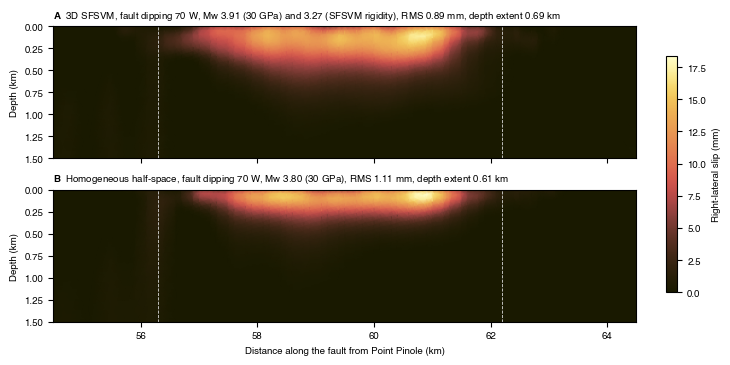

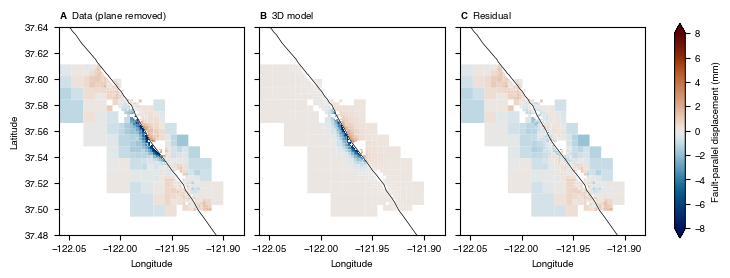

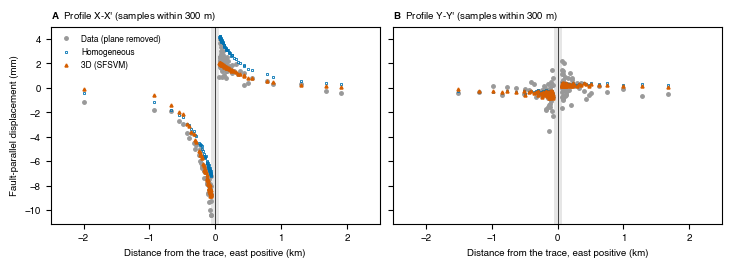

In [10]:
lcurve_hom = pd.read_csv(os.path.join(dir_hom, "homogeneous_lcurve.csv"))


def save(fig, name):
    """Save a figure as png and pdf in the figure folder.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        The figure.
    name : str
        File name without extension; the dip of the preferred model (`model_config.selected_dip_tag`) is appended.
    """
    name = f"{name}_{cfg.selected_dip_tag}"
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(fig_dir, f"{name}.{ext}"), dpi=300, facecolor="white")
    print("saved", os.path.join(fig_dir, name + ".png"))


# L-curves
fig, ax = plt.subplots(figsize=(8.5 * cm, 7.0 * cm), constrained_layout=True)
for table, corner, colour, label in ((lcurve, sigma, OKABE["vermillion"], "3D (SFSVM)"),
                                     (lcurve_hom, float(lcurve_hom.corner.iloc[0]), OKABE["blue"], "Homogeneous")):
    ax.loglog(np.sqrt(table.chi2_fitted), table.roughness, "o-", color=colour, ms=2.5, lw=0.8, label=label)
    at = np.argmin(np.abs(table.sigma - corner))
    ax.loglog(np.sqrt(table.chi2_fitted.iloc[at]), table.roughness.iloc[at], "*", color="k", ms=8)
    ax.annotate(f"Corner $\\sigma$ = {corner:.1f}", (np.sqrt(table.chi2_fitted.iloc[at]), table.roughness.iloc[at]),
                textcoords="offset points", xytext=(6, -10), fontsize=6.5, color=colour)
ax.set_xlabel("Weighted misfit, $\\sqrt{\\chi^2}$ of the fitted samples")
ax.set_ylabel("Roughness (prior-weighted norm)")
ax.legend(loc="upper right")
utils.panel_title(ax, "A", "L-curves (star: corner)")
save(fig, "figS_model_lcurve")

# slip on the unrolled fault, 3D and homogeneous
triangulation = mtri.Triangulation(tents.imp_km, tents.imp_depth_km, tents.sub_faces)
fig, axes = plt.subplots(2, 1, figsize=(18.3 * cm, 9.0 * cm), sharex=True, constrained_layout=True)
vmax = float(max(slip.max(), homogeneous["slip_mm"].max()))
# the SSE section ends are thin dashed lines; each label gives the elastic structure, the dip and the key numbers
for ax, letter, values, title in ((axes[0], "A", slip,
                                   f"3D SFSVM, fault dipping {cfg.selected_dip_label}, Mw {numbers['Mw_30gpa']:.2f} (30 GPa) and {numbers['Mw_sfcvm']:.2f} "
                                   f"(SFSVM rigidity), RMS {numbers['rms_mm']:.2f} mm, depth extent {numbers['depth90_m'] / 1e3:.2f} km"),
                                  (axes[1], "B", homogeneous["slip_mm"],
                                   f"Homogeneous half-space, fault dipping {cfg.selected_dip_label}, Mw {float(homogeneous['Mw_30gpa']):.2f} (30 GPa), "
                                   f"RMS {float(homogeneous['rms_mm']):.2f} mm, depth extent {float(homogeneous['depth90_m']) / 1e3:.2f} km")):
    image = ax.tripcolor(triangulation, values, shading="gouraud", cmap=cmc.lajolla, vmin=0, vmax=vmax)
    for section_end_km in (creep_lo_km, creep_hi_km):
        ax.axvline(section_end_km, color="0.85", ls="--", lw=0.6)
    ax.set_ylim(1.5, 0)
    ax.set_xlim(54.5, 64.5)
    ax.set_ylabel("Depth (km)")
    utils.panel_title(ax, letter, title)
axes[1].set_xlabel("Distance along the fault from Point Pinole (km)")
fig.colorbar(image, ax=axes, label="Right-lateral slip (mm)", shrink=0.8)
save(fig, "figS_model_slip")

# data / model / residual maps on the quadtree blocks
block_polygons = [np.c_[lon_row, lat_row] for lon_row, lat_row in zip(model_data["block_lon"], model_data["block_lat"])]
fig, axes = plt.subplots(1, 3, figsize=(18.3 * cm, 8.0 * cm), sharex=True, sharey=True, constrained_layout=True)
limit = 8.0
for ax, letter, values, title in ((axes[0], "A", data_plane_removed_mm, "Data (plane removed)"),
                                  (axes[1], "B", model_mm, "3D model"), (axes[2], "C", residual_mm, "Residual")):
    shown = np.where(keep, values, np.nan)
    collection = PolyCollection(block_polygons, array=shown, cmap=cmc.vik, edgecolors="none")
    collection.set_clim(-limit, limit)
    ax.add_collection(collection)
    ax.plot(trace["lonlat"][:, 0], trace["lonlat"][:, 1], color="k", lw=0.5)
    ax.set_xlim(-122.06, -121.88)
    ax.set_ylim(37.48, 37.64)
    ax.set_aspect(1 / np.cos(np.deg2rad(37.56)))
    utils.panel_title(ax, letter, title)
    ax.set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
fig.colorbar(collection, ax=axes, label="Fault-parallel displacement (mm)", shrink=0.7, extend="both")
save(fig, "figS_model_fit_maps")

# across-fault profiles X-X' and Y-Y' (samples within 300 m of each line)
fig, axes = plt.subplots(1, 2, figsize=(18.3 * cm, 6.5 * cm), sharey=True, constrained_layout=True)
for ax, letter, line in ((axes[0], "A", "X"), (axes[1], "B", "Y")):
    on_line, _ = model_utils.profile_samples(model_data["sample_lon"], model_data["sample_lat"], fig2_inputs[f"prof_fp_{line}_ends"],
                                             fig2_inputs["epsg"])
    shown = on_line & keep
    order = np.argsort(signed_d_km[shown])
    d_shown = signed_d_km[shown][order]
    ax.plot(d_shown, data_plane_removed_mm[shown][order], "o", color=OKABE["grey"], ms=2.5, label="Data (plane removed)")
    ax.plot(d_shown, homogeneous["model_mm"][shown][order], "s", color=OKABE["blue"], ms=2.0, mfc="none", mew=0.6, label="Homogeneous")
    ax.plot(d_shown, model_mm[shown][order], "^", color=OKABE["vermillion"], ms=2.2, label="3D (SFSVM)")
    ax.axvline(0, color="k", lw=0.5)
    ax.axvspan(-cfg.near_trace_cut_km, cfg.near_trace_cut_km, color="0.9", lw=0)
    ax.set_xlim(-2.5, 2.5)
    ax.set_xlabel("Distance from the trace, east positive (km)")
    utils.panel_title(ax, letter, f"Profile {line}-{line}' (samples within 300 m)")
axes[0].set_ylabel("Fault-parallel displacement (mm)")
axes[0].legend(loc="upper left")
save(fig, "figS_model_profiles")

# the SFSVM shear modulus at 50 m depth and across X-X', unshifted and aligned on the trace, with the published fault dips
sys.path.insert(0, os.path.join(repo_dir, "scripts", "model_plots"))
import plot_materials                                                   # noqa: E402
plot_materials.main(paths_sfcvm["spatialdb"], fig_dir)

## 11. Monte Carlo of correlated noise

The uncertainty of each number from data noise is estimated with synthetic data sets (Wright 2003; Sudhaus & Jónsson
2009). Each realisation $k$ is the model prediction plus correlated noise,

$$\mathbf{d}_k = G\mathbf{s} + B\mathbf{a} + L\,\mathbf{z}_k , \qquad L L^{T} = C ,$$

where $G\mathbf{s} + B\mathbf{a}$ is the preferred slip model plus its fitted plane at the samples (mm), $C$ the full
covariance of the noise model (notebook 07, section 4; `model_utils.covariance_matrix`) with the exponential terms and
$n^2/N_i^{0.5}$ on the diagonal, $L$ its Cholesky factor, and $\mathbf{z}_k$ a vector of independent standard normal
values (`model_utils.correlated_noise`, numpy seed `model_config.mc_seed`). Each of the 100 realisations is inverted
with the same settings at the corner $\sigma$ of section 5, and the numbers of section 6 are computed. The standard
deviation and the 2.5 and 97.5 percentiles of each number over the realisations are its uncertainty; the Monte Carlo
mean is printed next to the model value.

  10 realisations (4.0 min)


  20 realisations (7.9 min)


  30 realisations (11.9 min)


  40 realisations (15.7 min)


  50 realisations (19.6 min)


  60 realisations (23.6 min)


... (5 outputs left out)

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


saved /Users/dlindsay/work/proj_TulePond_DISP_release/Figures_2026-11-01/figS_model_montecarlo_dip70w.png


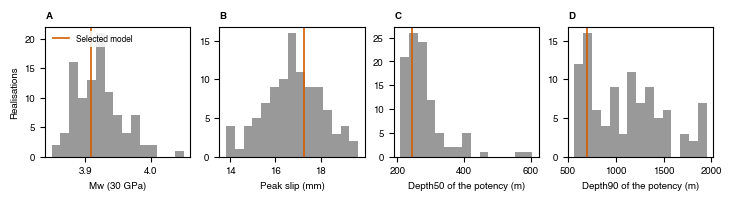

In [11]:
t0 = time.time()
noise_cd = model_utils.covariance_matrix(np.asarray(samples.x, float), np.asarray(samples.y, float), np.asarray(samples.wgt, float),
                                         cov_p, cfg.mc_noise_nugget_power)
noise = model_utils.correlated_noise(noise_cd, cfg.mc_n_realisations, cfg.mc_seed)
prediction_mm = model_mm + plane_mm
mc_rows = []
for k in range(cfg.mc_n_realisations):
    fault_k, data_k, _ = solve_3d(sigma, vel=prediction_mm + noise[k])
    numbers_k = model_utils.tent_numbers(fault_k.slip[:, 0].copy(), data_k, tents, keep, west_near, east_near, cfg.mu_ref_pa, mu_harmonic)
    mc_rows.append(dict(realisation=k, **numbers_k))
    if k % 10 == 9:
        print(f"  {k + 1} realisations ({(time.time() - t0) / 60:.1f} min)", flush=True)
montecarlo = pd.DataFrame(mc_rows)
montecarlo.to_csv(os.path.join(out_dir, "montecarlo_realisations.csv"), index=False)
mc_keys = ["Mw_30gpa", "Mw_sfcvm", "potency_m3", "peak_slip_mm", "peak_depth_m", "depth50_m", "depth90_m", "rms_mm"]
mc_summary = pd.DataFrame([dict(quantity=key, model=numbers[key], mc_mean=montecarlo[key].mean(), mc_sd=montecarlo[key].std(ddof=1),
                                mc_p2_5=np.percentile(montecarlo[key], 2.5), mc_p97_5=np.percentile(montecarlo[key], 97.5))
                           for key in mc_keys])
mc_summary.to_csv(os.path.join(out_dir, "montecarlo_summary.csv"), index=False)
print(mc_summary.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 4, figsize=(18.3 * cm, 4.8 * cm), constrained_layout=True)
for ax, letter, key, label in ((axes[0], "A", "Mw_30gpa", "Mw (30 GPa)"), (axes[1], "B", "peak_slip_mm", "Peak slip (mm)"),
                               (axes[2], "C", "depth50_m", "Depth50 of the potency (m)"), (axes[3], "D", "depth90_m", "Depth90 of the potency (m)")):
    ax.hist(montecarlo[key], bins=15, color=OKABE["grey"])
    ax.axvline(numbers[key], color=OKABE["vermillion"], lw=1.2, label="Selected model")
    ax.set_xlabel(label)
    utils.panel_title(ax, letter)
axes[0].set_ylabel("Realisations")
axes[0].legend(loc="upper left")
save(fig, "figS_model_montecarlo")

## 12. Stress drop

The stress drop of a long strike-slip fault that reaches the free surface is (Knopoff 1958; Kanamori & Anderson 1975,
Eq. 1; `model_utils.strike_slip_stress_drop_pa`)

$$\Delta\sigma = \frac{2}{\pi}\,\mu\,\frac{\bar{d}}{w} , \qquad w = \frac{D}{\sin\delta} ,$$

where $\Delta\sigma$ is the stress drop (Pa), $\mu$ the rigidity (Pa), $\bar{d}$ the uniform slip (m), $w$ the
down-dip width of the slipping part of the fault (m), $D$ the depth of its lower edge (m), and $\delta$ the fault dip
(70°, `model_config.selected_dip_deg`).

$\bar{d}$ and $D$ come from the best model of the fixed-depth scan (`scripts/sensitivity/depth_scan.py`, stored
`depth_scan.csv`). For each depth $D$, the slip pattern $\boldsymbol{\phi}_D$ (`model_utils.uniform_slip_shape`) is 1
at the impulse vertices from the surface to $D$ inside the SSE section, tapered linearly to 0 over 0.5 km at each end
of the section, and 0 elsewhere. One amplitude and a plane are fitted to the fitted samples by least squares with
equal weights and no smoothing (`model_utils.uniform_slip_fit`):

$$\mathbf{d} \approx \bar{d}\,G\boldsymbol{\phi}_D + B\mathbf{a} .$$

The best $D$ is the one with the smallest RMS of the fitted samples.

Check: the best row is solved again here and must equal the stored scan.

The stress drop is given for $\mu = 30$ GPa and for the harmonic mean (Vavrycuk 2013) of the SFSVM rigidity west and
east of the fault, $\mu = 2\,\bar\mu_W \bar\mu_E / (\bar\mu_W + \bar\mu_E)$, where $\bar\mu_W$ and $\bar\mu_E$ are the
area-weighted means of the PyLith cells beside the fault triangles of the SSE section from the surface to $D$, on the
west and east side (section 4).

In [12]:
scan = pd.read_csv(cfg.archived["depth_scan"])
best = scan.loc[scan.rms_all_mm.idxmin()]
best_depth_km = float(best.D_km)
shape = model_utils.uniform_slip_shape(tents, (creep_lo_km, creep_hi_km), cfg.depth_scan_taper_km, best_depth_km)
best_slip_mm, best_residual = model_utils.uniform_slip_fit(G, shape, samples.vel.astype(float), np.asarray(samples.x, float),
                                                           np.asarray(samples.y, float), keep)
best_rms = float(np.sqrt(np.mean(best_residual[keep] ** 2)))
print(f"best D {best_depth_km:.2f} km: slip {best_slip_mm:.3f} mm here vs {best.slip_mm:.3f} in the scan; RMS {best_rms:.4f} vs {best.rms_all_mm:.4f} mm")
assert abs(best_slip_mm - best.slip_mm) < 1e-6 * best.slip_mm and abs(best_rms - best.rms_all_mm) < 1e-6, "the scan does not reproduce"
print("Check passed: the best fixed-depth row reproduces")
upper = (tents.tri_depth_m <= best_depth_km * 1e3) & (tents.tri_km >= creep_lo_km) & (tents.tri_km <= creep_hi_km)
mu_west_upper = float(np.average(mu_west[upper], weights=tents.tri_area[upper]))
mu_east_upper = float(np.average(mu_east[upper], weights=tents.tri_area[upper]))
mu_harmonic_upper = float(model_utils.harmonic_mean_rigidity(mu_west_upper, mu_east_upper))
width_m = best_depth_km * 1e3 / np.sin(np.radians(cfg.selected_dip_deg))      # down-dip width of the slipping part
stress_drop = pd.DataFrame([dict(rigidity=label, mu_gpa=mu / 1e9, slip_mm=best_slip_mm, depth_m=best_depth_km * 1e3,
                                 dip_deg=cfg.selected_dip_deg, width_m=width_m,
                                 stress_drop_kpa=model_utils.strike_slip_stress_drop_pa(mu, best_slip_mm * 1e-3, width_m) / 1e3)
                            for label, mu in (("30 GPa", cfg.mu_ref_pa), ("harmonic SFSVM west/east, 0 to D", mu_harmonic_upper))])
stress_drop.to_csv(os.path.join(out_dir, "stress_drop.csv"), index=False)
print(f"SFSVM beside the fault, SSE section, 0-{best_depth_km * 1e3:.0f} m ({upper.sum()} triangles): west {mu_west_upper / 1e9:.3f}, "
      f"east {mu_east_upper / 1e9:.3f}, harmonic {mu_harmonic_upper / 1e9:.3f} GPa")
print(stress_drop.round(3).to_string(index=False))

best D 0.55 km: slip 10.824 mm here vs 10.824 in the scan; RMS 1.0771 vs 1.0771 mm
Check passed: the best fixed-depth row reproduces
SFSVM beside the fault, SSE section, 0-550 m (2293 triangles): west 2.180, east 2.354, harmonic 2.264 GPa
                        rigidity  mu_gpa  slip_mm  depth_m  dip_deg  width_m  stress_drop_kpa
                          30 GPa  30.000   10.824    550.0     70.0  585.298          353.185
harmonic SFSVM west/east, 0 to D   2.264   10.824    550.0     70.0  585.298           26.648


## 13. Products and the number registry

`selected_model.npz` holds what Fig 2 (notebook 14) draws: the samples and their blocks, the data, the plane, the
model, the residual, `keep`, the signed distance from the trace and the position along strike, the crossing steps of
panel K, the slip on the tents, and Mw. The numbers of the paper are registered with the stats file
`09_selected_stats.txt`.

In [13]:
selected_file = os.path.join(out_dir, "selected_model.npz")
np.savez(selected_file, sample_lon=model_data["sample_lon"], sample_lat=model_data["sample_lat"], block_lon=model_data["block_lon"],
         block_lat=model_data["block_lat"], data_mm=samples.vel.copy(), plane_mm=plane_mm, model_mm=model_mm,
         data_plane_removed_mm=data_plane_removed_mm, residual_mm=residual_mm, keep=keep, signed_d_km=signed_d_km,
         sample_km_pp=sample_km_pp, crossing_km=crossing_km, data_step_mm=data_step, model_step_mm=model_step,
         step_inner_km=cfg.fig2k_inner_km, step_outer_km=cfg.fig2k_outer_km, slip_mm=slip, imp_km=tents.imp_km,
         imp_depth_km=tents.imp_depth_km, sub_faces=tents.sub_faces, imp_xyz=tents.imp_xyz, mu_harmonic_pa=mu_harmonic,
         **{k: v for k, v in numbers.items()}, run=cfg.gf_run, field_fingerprint=field_fingerprint,
         provenance=f"{notebook} {made}: {cfg.gf_run}, settings of model_config, sigma {sigma:.3f}")
mc = mc_summary.set_index("quantity")
stats = REG.sidecar("09_selected", cfg.summary() + [comparison.to_string(index=False), model_comparison.to_string(index=False),
                                                      mc_summary.to_string(index=False), deflection.to_string(index=False),
                                                      stress_drop.to_string(index=False)]
                    + [f"{k} = {v}" for k, v in numbers.items()])
where = "M8"
REG.register("09_n_samples_fitted", numbers["n_fitted"], "count", 0, where, "section 3", stats)
REG.register("09_sigma", sigma, "mm", 1, where, "section 5", stats)
REG.register("09_sigma_base_corner", sigma_base, "mm", 1, where, "section 5", stats)
REG.register("09_mw_30gpa", numbers["Mw_30gpa"], "Mw", 2, where, "section 6", stats)
REG.register("09_mw_harmonic", numbers["Mw_sfcvm"], "Mw", 2, where, "section 6", stats)
REG.register("09_mu_effective_harmonic_gpa", numbers["mu_effective_gpa"], "GPa", 1, where, "section 6", stats)
REG.register("09_potency_m3", numbers["potency_m3"], "m3", 0, where, "section 6", stats)
REG.register("09_peak_slip_mm", numbers["peak_slip_mm"], "mm", 1, where, "section 6", stats)
REG.register("09_peak_depth_m", numbers["peak_depth_m"], "m", 0, where, "section 6", stats)
REG.register("09_depth50_m", numbers["depth50_m"], "m", 0, where, "section 6", stats)
REG.register("09_depth90_m", numbers["depth90_m"], "m", 0, where, "section 6", stats)
REG.register("09_rms_mm", numbers["rms_mm"], "mm", 2, where, "section 6", stats)
REG.register("09_rms_west500_mm", numbers["rms_west_mm"], "mm", 2, where, "section 6", stats)
REG.register("09_rms_east500_mm", numbers["rms_east_mm"], "mm", 2, where, "section 6", stats)
REG.register("09_band_step_mean_mm", numbers["band_step_mean_mm"], "mm", 2, where, "section 6", stats)
REG.register("09_band_step_rms_mm", numbers["band_step_rms_mm"], "mm", 2, where, "section 6", stats)
for key, tag, units, precision in (("Mw_30gpa", "mw_30gpa", "Mw", 3), ("Mw_sfcvm", "mw_harmonic", "Mw", 3),
                                   ("potency_m3", "potency_m3", "m3", 0), ("peak_slip_mm", "peak_slip_mm", "mm", 2),
                                   ("depth50_m", "depth50_m", "m", 0), ("depth90_m", "depth90_m", "m", 0)):
    REG.register(f"09_mc_{tag}_sd", mc.loc[key, "mc_sd"], units, precision, where, "section 11", stats)
    REG.register(f"09_mc_{tag}_p2_5", mc.loc[key, "mc_p2_5"], units, precision, where, "section 11", stats)
    REG.register(f"09_mc_{tag}_p97_5", mc.loc[key, "mc_p97_5"], units, precision, where, "section 11", stats)
for _, row in deflection[deflection.far_band == "selected"].iterrows():
    tag = {"Data (3D model's plane removed)": "data", "3D model": "model", "Data (homogeneous model's plane removed)": "data_homplane",
           "Homogeneous model": "hom"}[row.field]
    REG.register(f"09_deflection_{tag}_west_mm", row.west_mm, "mm", 2, "M7", "section 9", stats)
    REG.register(f"09_deflection_{tag}_east_mm", row.east_mm, "mm", 2, "M7", "section 9", stats)
REG.register("09_stress_drop_depth_m", best_depth_km * 1e3, "m", 0, where, "section 12", stats)
REG.register("09_stress_drop_slip_mm", best_slip_mm, "mm", 1, where, "section 12", stats)
REG.register("09_stress_drop_mu_harmonic_gpa", mu_harmonic_upper / 1e9, "GPa", 2, where, "section 12", stats)
REG.register("09_stress_drop_width_m", width_m, "m", 0, where, "section 12", stats)
REG.register("09_stress_drop_30gpa_kpa", stress_drop.stress_drop_kpa.iloc[0], "kPa", 0, where, "section 12", stats)
REG.register("09_stress_drop_harmonic_kpa", stress_drop.stress_drop_kpa.iloc[1], "kPa", 0, where, "section 12", stats)
REG.render()
print(f"wrote {selected_file}")

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/09_model_3d/09_selected_stats.txt
  registered 09_n_samples_fitted = 1787 count  -> M8
  registered 09_sigma = 49.6 mm  -> M8
  registered 09_sigma_base_corner = 52.4 mm  -> M8
  registered 09_mw_30gpa = 3.91 Mw  -> M8
  registered 09_mw_harmonic = 3.27 Mw  -> M8
  registered 09_mu_effective_harmonic_gpa = 3.3 GPa  -> M8
  registered 09_potency_m3 = 30671 m3  -> M8
  registered 09_peak_slip_mm = 17.3 mm  -> M8
  registered 09_peak_depth_m = 111 m  -> M8
  registered 09_depth50_m = 245 m  -> M8
  registered 09_depth90_m = 695 m  -> M8


  registered 09_rms_mm = 0.89 mm  -> M8
  registered 09_rms_west500_mm = 0.85 mm  -> M8
  registered 09_rms_east500_mm = 0.98 mm  -> M8
  registered 09_band_step_mean_mm = 0.21 mm  -> M8
  registered 09_band_step_rms_mm = 0.48 mm  -> M8
  registered 09_mc_mw_30gpa_sd = 0.036 Mw  -> M8
  registered 09_mc_mw_30gpa_p2_5 = 3.868 Mw  -> M8
  registered 09_mc_mw_30gpa_p97_5 = 4.000 Mw  -> M8
  registered 09_mc_mw_harmonic_sd = 0.143 Mw  -> M8
  registered 09_mc_mw_harmonic_p2_5 = 3.157 Mw  -> M8
  registered 09_mc_mw_harmonic_p97_5 = 3.666 Mw  -> M8


  registered 09_mc_potency_m3_sd = 4252 m3  -> M8
  registered 09_mc_potency_m3_p2_5 = 26558 m3  -> M8
  registered 09_mc_potency_m3_p97_5 = 41991 m3  -> M8
  registered 09_mc_peak_slip_mm_sd = 1.26 mm  -> M8
  registered 09_mc_peak_slip_mm_p2_5 = 14.18 mm  -> M8
  registered 09_mc_peak_slip_mm_p97_5 = 19.12 mm  -> M8
  registered 09_mc_depth50_m_sd = 67 m  -> M8
  registered 09_mc_depth50_m_p2_5 = 215 m  -> M8
  registered 09_mc_depth50_m_p97_5 = 431 m  -> M8
  registered 09_mc_depth90_m_sd = 393 m  -> M8
  registered 09_mc_depth90_m_p2_5 = 592 m  -> M8
  registered 09_mc_depth90_m_p97_5 = 1904 m  -> M8
  registered 09_deflection_data_west_mm = -4.93 mm  -> M7
  registered 09_deflection_data_east_mm = 1.86 mm  -> M7


  registered 09_deflection_model_west_mm = -5.34 mm  -> M7
  registered 09_deflection_model_east_mm = 1.37 mm  -> M7
  registered 09_deflection_data_homplane_west_mm = -4.68 mm  -> M7
  registered 09_deflection_data_homplane_east_mm = 1.67 mm  -> M7
  registered 09_deflection_hom_west_mm = -4.15 mm  -> M7
  registered 09_deflection_hom_east_mm = 2.07 mm  -> M7
  registered 09_stress_drop_depth_m = 550 m  -> M8
  registered 09_stress_drop_slip_mm = 10.8 mm  -> M8
  registered 09_stress_drop_mu_harmonic_gpa = 2.26 GPa  -> M8
  registered 09_stress_drop_width_m = 585 m  -> M8
  registered 09_stress_drop_30gpa_kpa = 353 kPa  -> M8
  registered 09_stress_drop_harmonic_kpa = 27 kPa  -> M8


Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/paper_numbers.md
wrote /Users/dlindsay/work/proj_TulePond_DISP_release/outputs/09_model_3d/selected_model.npz
